In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set random seed for reproducibility
RANDOM_STATE = 42
warnings.filterwarnings('ignore')

In [5]:
# Load the traffic dataset from an Excel or CSV file

file_path = "Dataset_Uber_Traffic_Combined.xlsx"  

if file_path.endswith(".csv"):
    df = pd.read_csv(file_path)
else:
    df = pd.read_excel(file_path)

In [6]:
# Display the first five records to understand the data
print(df.head())

             DateTime  Junction  Vehicles           ID  temperature_2m (°C)  \
0 2015-11-01 00:00:00         1        15  20151101001                 20.8   
1 2015-11-01 00:00:00         2         6  20151101002                 20.8   
2 2015-11-01 01:00:00         1        13  20151101011                 20.6   
3 2015-11-01 01:00:00         2         6  20151101012                 20.6   
4 2015-11-01 02:00:00         1        10  20151101021                 22.1   

   relative_humidity_2m (%)  precipitation (mm)  rain (mm)  
0                        83                 0.0        0.0  
1                        83                 0.0        0.0  
2                        83                 0.0        0.0  
3                        83                 0.0        0.0  
4                        76                 0.0        0.0  


In [7]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

Dataset Shape: (48120, 8)


In [8]:
df.shape

(48120, 8)

In [9]:
# Display column names
print("Columns:", df.columns.tolist())

Columns: ['DateTime', 'Junction', 'Vehicles', 'ID', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'precipitation (mm)', 'rain (mm)']


In [10]:
df.describe()

,DateTime,Junction,Vehicles,ID,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),rain (mm)
count,48120,48120.000000,48120.000000,4.812000e+04,48120.000000,48120.000000,48120.000000,48120.000000
mean,2016-09-19 06:03:56.109725,2.180549,22.791334,2.016330e+10,26.474944,55.798109,0.078387,0.078387
min,2015-11-01 00:00:00,1.000000,1.000000,2.015110e+10,12.400000,8.000000,0.000000,0.000000
25%,2016-04-16 01:45:00,1.000000,9.000000,2.016042e+10,22.900000,36.000000,0.000000,0.000000
50%,2016-09-30 03:30:00,2.000000,15.000000,2.016093e+10,26.100000,56.000000,0.000000,0.000000
75%,2017-02-25 16:00:00,3.000000,29.000000,2.017023e+10,29.600000,75.000000,0.000000,0.000000
max,2017-06-30 23:00:00,4.000000,180.000000,2.017063e+10,41.400000,99.000000,9.400000,9.400000
std,NaN,0.966955,20.750063,5.944854e+06,5.343974,22.852496,0.392051,0.392051


In [11]:
# Check column data types and missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DateTime                  48120 non-null  datetime64[us]
 1   Junction                  48120 non-null  int64         
 2   Vehicles                  48120 non-null  int64         
 3   ID                        48120 non-null  int64         
 4   temperature_2m (°C)       48120 non-null  float64       
 5   relative_humidity_2m (%)  48120 non-null  int64         
 6   precipitation (mm)        48120 non-null  float64       
 7   rain (mm)                 48120 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(4)
memory usage: 2.9 MB


In [12]:
print(df.isnull().sum())

DateTime                    0
Junction                    0
Vehicles                    0
ID                          0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
rain (mm)                   0
dtype: int64


# this provides there are no null values in the dataset

In [14]:
# Convert column names to lowercase and replace spaces with underscores

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Updated Column Names:")
print(df.columns.tolist())

Updated Column Names:
['datetime', 'junction', 'vehicles', 'id', 'temperature_2m_c', 'relative_humidity_2m', 'precipitation_mm', 'rain_mm']


In [15]:
# Identify timestamp, junction, and vehicle count columns

print(df.columns.tolist())

timestamp_col = "datetime"
junction_col = "junction"
vehicle_col = "vehicles"

# Verify that the required columns exist
required_columns = [timestamp_col, junction_col, vehicle_col]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Column '{col}' not found. Check your dataset.")

print("\nRequired columns identified successfully.")

['datetime', 'junction', 'vehicles', 'id', 'temperature_2m_c', 'relative_humidity_2m', 'precipitation_mm', 'rain_mm']

Required columns identified successfully.


In [17]:
# Convert timestamp and vehicle count columns to appropriate data types

df[timestamp_col] = pd.to_datetime(
    df[timestamp_col],
    errors="coerce"
)

df[vehicle_col] = pd.to_numeric(
    df[vehicle_col],
    errors="coerce"
)

# Remove rows with missing essential values
df = df.dropna(
    subset=[timestamp_col, junction_col, vehicle_col]
).copy()

# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert junction identifiers to strings
df[junction_col] = df[junction_col].astype("string")

# Remove negative vehicle counts
df = df[df[vehicle_col] >= 0].copy()

# Fill missing values in other numeric columns using the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if col != vehicle_col:
        df[col] = df[col].fillna(df[col].median())


In [18]:
# Display the cleaned dataset
print("Shape After Cleaning:", df.shape)
display(df.head())

Shape After Cleaning: (48120, 8)


,datetime,junction,vehicles,id,temperature_2m_c,relative_humidity_2m,precipitation_mm,rain_mm
0,2015-11-01 00:00:00,1,15,20151101001,20.8,83,0.0,0.0
1,2015-11-01 00:00:00,2,6,20151101002,20.8,83,0.0,0.0
2,2015-11-01 01:00:00,1,13,20151101011,20.6,83,0.0,0.0
3,2015-11-01 01:00:00,2,6,20151101012,20.6,83,0.0,0.0
4,2015-11-01 02:00:00,1,10,20151101021,22.1,76,0.0,0.0


In [19]:
print("Missing Values:")
display(df.isnull().sum())

Missing Values:


datetime                0
junction                0
vehicles                0
id                      0
temperature_2m_c        0
relative_humidity_2m    0
precipitation_mm        0
rain_mm                 0
dtype: int64

In [21]:
# Round timestamps down to the nearest hour

df["hour_timestamp"] = df[timestamp_col].dt.floor("h")

# Aggregate vehicle counts for each junction and hour
hourly_df = (
    df.groupby([junction_col, "hour_timestamp"], as_index=False)
    .agg({vehicle_col: "sum"})
)

# Rename timestamp column
hourly_df = hourly_df.rename(
    columns={"hour_timestamp": "datetime"}
)

# Sort records chronologically for each junction
hourly_df = hourly_df.sort_values(
    [junction_col, "datetime"]
).reset_index(drop=True)


In [22]:
# Display hourly aggregated traffic data
print(hourly_df.head(10))

  junction            datetime  vehicles
0        1 2015-11-01 00:00:00        15
1        1 2015-11-01 01:00:00        13
2        1 2015-11-01 02:00:00        10
3        1 2015-11-01 03:00:00         7
4        1 2015-11-01 04:00:00         9
5        1 2015-11-01 05:00:00         6
6        1 2015-11-01 06:00:00         9
7        1 2015-11-01 07:00:00         8
8        1 2015-11-01 08:00:00        11
9        1 2015-11-01 09:00:00        12


In [23]:
print("Hourly Dataset Shape:", hourly_df.shape)

Hourly Dataset Shape: (48120, 3)


In [24]:
# Standardize vehicle counts using StandardScaler

scaler = StandardScaler()

hourly_df["vehicle_count_standardized"] = scaler.fit_transform(
    hourly_df[[vehicle_col]]
)

# Display original and standardized values
display(
    hourly_df[
        [junction_col, "datetime", vehicle_col,
         "vehicle_count_standardized"]
    ].head()
)

,junction,datetime,vehicles,vehicle_count_standardized
0,1,2015-11-01 00:00:00,15,-0.375489
1,1,2015-11-01 01:00:00,13,-0.471875
2,1,2015-11-01 02:00:00,10,-0.616454
3,1,2015-11-01 03:00:00,7,-0.761034
4,1,2015-11-01 04:00:00,9,-0.664648


In [25]:
# Extract time-related features from the timestamp

hourly_df["hour"] = hourly_df["datetime"].dt.hour

hourly_df["day_of_week"] = hourly_df["datetime"].dt.dayofweek

hourly_df["day_of_month"] = hourly_df["datetime"].dt.day

hourly_df["month"] = hourly_df["datetime"].dt.month

hourly_df["year"] = hourly_df["datetime"].dt.year

hourly_df["day_of_year"] = hourly_df["datetime"].dt.dayofyear

# Identify weekends (Saturday = 5, Sunday = 6)
hourly_df["is_weekend"] = (
    hourly_df["day_of_week"] >= 5
).astype(int)

# Identify morning and evening rush hours
hourly_df["is_morning_rush"] = (
    hourly_df["hour"].between(7, 10)
).astype(int)

hourly_df["is_evening_rush"] = (
    hourly_df["hour"].between(16, 19)
).astype(int)

# Display the new features
display(hourly_df.head())

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,is_weekend,is_morning_rush,is_evening_rush
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,1,0,0
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,1,0,0
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,1,0,0
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,1,0,0
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,1,0,0


In [26]:
# Add dates of relevant local holidays, festivals, or special events.
# Replace these example dates with verified event dates.

special_event_dates = [
    # "2026-08-15",
    # "2026-10-20"
]

special_event_dates = pd.to_datetime(
    special_event_dates
).normalize()

# Mark records occurring on special event dates
hourly_df["is_special_event"] = (
    hourly_df["datetime"].dt.normalize()
    .isin(special_event_dates)
).astype(int)

display(
    hourly_df[
        ["datetime", "is_weekend", "is_special_event"]
    ].head()
)

,datetime,is_weekend,is_special_event
0,2015-11-01 00:00:00,1,0
1,2015-11-01 01:00:00,1,0
2,2015-11-01 02:00:00,1,0
3,2015-11-01 03:00:00,1,0
4,2015-11-01 04:00:00,1,0


In [27]:
# Sort records before calculating lag features
hourly_df = hourly_df.sort_values(
    [junction_col, "datetime"]
).reset_index(drop=True)

# Capture traffic counts from previous hours
for lag in [1, 2, 3, 6, 12, 24]:
    hourly_df[f"vehicle_count_lag_{lag}h"] = (
        hourly_df.groupby(junction_col)[vehicle_col].shift(lag)
    )

# Calculate rolling averages using previous observations only
hourly_df["rolling_mean_3h"] = (
    hourly_df.groupby(junction_col)[vehicle_col]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

hourly_df["rolling_mean_24h"] = (
    hourly_df.groupby(junction_col)[vehicle_col]
    .transform(lambda x: x.shift(1).rolling(24).mean())
)

# Display lag features
display(hourly_df.head(30))

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,is_evening_rush,is_special_event,vehicle_count_lag_1h,vehicle_count_lag_2h,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,...,0,0,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,...,0,0,13.0,15.0,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,...,0,0,10.0,13.0,15.0,NaN,NaN,NaN,12.666667,NaN
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,...,0,0,7.0,10.0,13.0,NaN,NaN,NaN,10.000000,NaN
5,1,2015-11-01 05:00:00,6,-0.809227,5,6,1,11,2015,305,...,0,0,9.0,7.0,10.0,NaN,NaN,NaN,8.666667,NaN
6,1,2015-11-01 06:00:00,9,-0.664648,6,6,1,11,2015,305,...,0,0,6.0,9.0,7.0,15.0,NaN,NaN,7.333333,NaN
7,1,2015-11-01 07:00:00,8,-0.712841,7,6,1,11,2015,305,...,0,0,9.0,6.0,9.0,13.0,NaN,NaN,8.000000,NaN
8,1,2015-11-01 08:00:00,11,-0.568261,8,6,1,11,2015,305,...,0,0,8.0,9.0,6.0,10.0,NaN,NaN,7.666667,NaN
9,1,2015-11-01 09:00:00,12,-0.520068,9,6,1,11,2015,305,...,0,0,11.0,8.0,9.0,7.0,NaN,NaN,9.333333,NaN


In [28]:
# Convert junction categories into binary indicator columns

junction_dummies = pd.get_dummies(
    hourly_df[junction_col],
    prefix="junction",
    dtype=int
)

hourly_df = pd.concat(
    [hourly_df, junction_dummies],
    axis=1
)

display(hourly_df.head())

,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
0,1,2015-11-01 00:00:00,15,-0.375489,0,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
1,1,2015-11-01 01:00:00,13,-0.471875,1,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
2,1,2015-11-01 02:00:00,10,-0.616454,2,6,1,11,2015,305,...,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,0
3,1,2015-11-01 03:00:00,7,-0.761034,3,6,1,11,2015,305,...,15.0,NaN,NaN,NaN,12.666667,NaN,1,0,0,0
4,1,2015-11-01 04:00:00,9,-0.664648,4,6,1,11,2015,305,...,13.0,NaN,NaN,NaN,10.000000,NaN,1,0,0,0


In [29]:
# Remove rows with missing lag features
# These rows lack sufficient historical observations.

lag_columns = [
    "vehicle_count_lag_1h",
    "vehicle_count_lag_2h",
    "vehicle_count_lag_3h",
    "vehicle_count_lag_6h",
    "vehicle_count_lag_12h",
    "vehicle_count_lag_24h",
    "rolling_mean_3h",
    "rolling_mean_24h"
]

model_df = hourly_df.dropna(
    subset=lag_columns
).copy()

print("Modeling Dataset Shape:", model_df.shape)

display(model_df.head())

Modeling Dataset Shape: (48024, 26)


,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
24,1,2015-11-02 00:00:00,14,-0.423682,0,0,2,11,2015,306,...,19.0,17.0,16.0,15.0,18.000000,13.625000,1,0,0,0
25,1,2015-11-02 01:00:00,12,-0.520068,1,0,2,11,2015,306,...,20.0,20.0,15.0,13.0,16.333333,13.583333,1,0,0,0
26,1,2015-11-02 02:00:00,14,-0.423682,2,0,2,11,2015,306,...,15.0,17.0,16.0,10.0,13.666667,13.541667,1,0,0,0
27,1,2015-11-02 03:00:00,12,-0.520068,3,0,2,11,2015,306,...,14.0,19.0,12.0,7.0,13.333333,13.708333,1,0,0,0
28,1,2015-11-02 04:00:00,12,-0.520068,4,0,2,11,2015,306,...,12.0,20.0,12.0,9.0,12.666667,13.916667,1,0,0,0


In [30]:
# Remove rows with missing lag features
# These rows lack sufficient historical observations.

lag_columns = [
    "vehicle_count_lag_1h",
    "vehicle_count_lag_2h",
    "vehicle_count_lag_3h",
    "vehicle_count_lag_6h",
    "vehicle_count_lag_12h",
    "vehicle_count_lag_24h",
    "rolling_mean_3h",
    "rolling_mean_24h"
]

model_df = hourly_df.dropna(
    subset=lag_columns
).copy()

print("Modeling Dataset Shape:", model_df.shape)

display(model_df.head())

Modeling Dataset Shape: (48024, 26)


,junction,datetime,vehicles,vehicle_count_standardized,hour,day_of_week,day_of_month,month,year,day_of_year,...,vehicle_count_lag_3h,vehicle_count_lag_6h,vehicle_count_lag_12h,vehicle_count_lag_24h,rolling_mean_3h,rolling_mean_24h,junction_1,junction_2,junction_3,junction_4
24,1,2015-11-02 00:00:00,14,-0.423682,0,0,2,11,2015,306,...,19.0,17.0,16.0,15.0,18.000000,13.625000,1,0,0,0
25,1,2015-11-02 01:00:00,12,-0.520068,1,0,2,11,2015,306,...,20.0,20.0,15.0,13.0,16.333333,13.583333,1,0,0,0
26,1,2015-11-02 02:00:00,14,-0.423682,2,0,2,11,2015,306,...,15.0,17.0,16.0,10.0,13.666667,13.541667,1,0,0,0
27,1,2015-11-02 03:00:00,12,-0.520068,3,0,2,11,2015,306,...,14.0,19.0,12.0,7.0,13.333333,13.708333,1,0,0,0
28,1,2015-11-02 04:00:00,12,-0.520068,4,0,2,11,2015,306,...,12.0,20.0,12.0,9.0,12.666667,13.916667,1,0,0,0


In [32]:
# Calculate correlations between numeric features

numeric_df = model_df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

# Rank features by their correlation with vehicle count
target_correlation = (
    correlation_matrix[vehicle_col]
    .drop(vehicle_col)
    .sort_values(key=abs, ascending=False)
)

print("Feature Correlations with Vehicle Count:")
display(target_correlation.to_frame(name="correlation"))

Feature Correlations with Vehicle Count:


,correlation
vehicle_count_standardized,1.000000
vehicle_count_lag_1h,0.970122
rolling_mean_3h,0.949120
vehicle_count_lag_2h,0.937090
vehicle_count_lag_24h,0.905146
vehicle_count_lag_3h,0.901064
rolling_mean_24h,0.880168
vehicle_count_lag_6h,0.783709
junction_1,0.708336
vehicle_count_lag_12h,0.687973


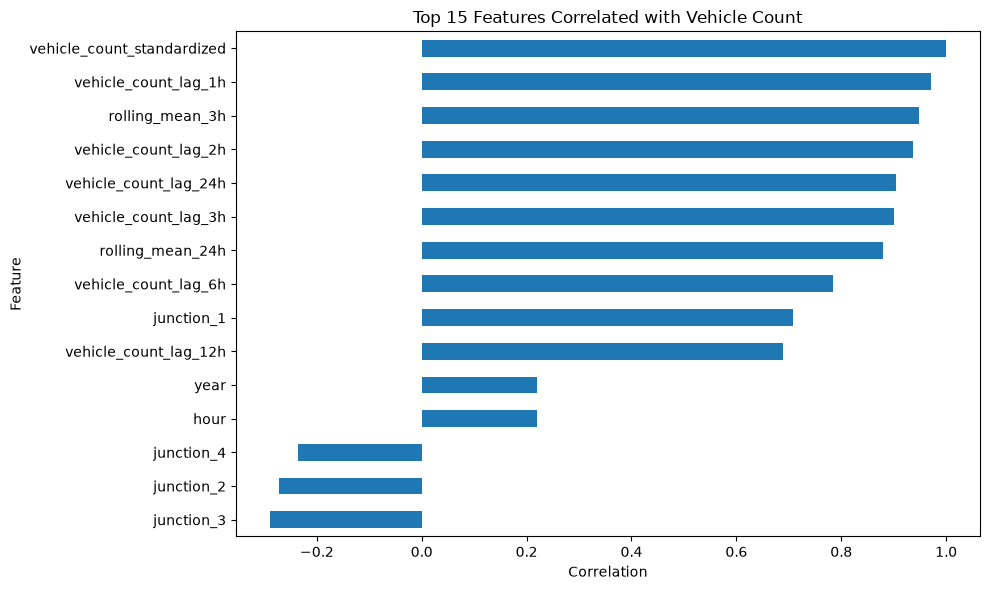

In [33]:
# Plot the top 15 correlated features
top_correlations = target_correlation.head(15).sort_values()

plt.figure(figsize=(10, 6))

top_correlations.plot(kind="barh")

plt.title("Top 15 Features Correlated with Vehicle Count")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

,Feature,Importance
0,vehicle_count_standardized,9.999965e-01
11,vehicle_count_lag_1h,6.487884e-07
17,rolling_mean_3h,6.393650e-07
14,vehicle_count_lag_6h,5.250609e-07
13,vehicle_count_lag_3h,4.511536e-07
15,vehicle_count_lag_12h,2.653425e-07
12,vehicle_count_lag_2h,2.473065e-07
1,hour,1.922259e-07
3,day_of_month,1.450175e-07
18,rolling_mean_24h,1.066685e-07


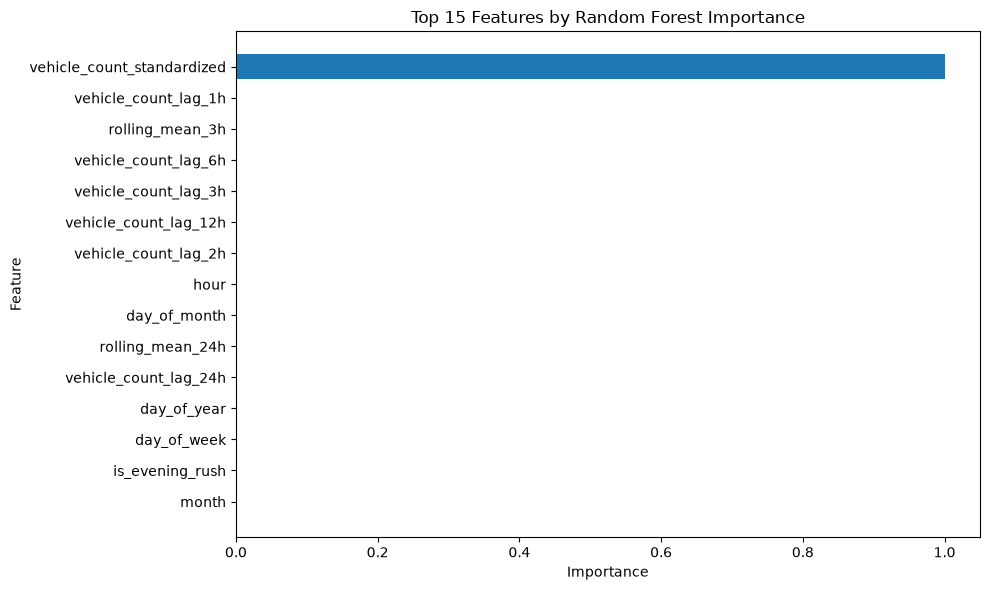

In [34]:
# Prepare features and target variable

excluded_columns = [
    vehicle_col,
    "datetime",
    junction_col,
    timestamp_col
]

feature_columns = [
    col for col in model_df.select_dtypes(include=np.number).columns
    if col not in excluded_columns
]

X = model_df[feature_columns]
y = model_df[vehicle_col]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train a Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=RANDOM_STATE,
    min_samples_leaf=2,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Calculate feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

# Visualize the top 15 important features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features by Random Forest Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [37]:
# Select features whose importance is at least the mean importance

selector = SelectFromModel(
    rf_model,
    threshold="mean",
    prefit=True
)

selected_features = X.columns[selector.get_support()].tolist()

print("Original Number of Features:", len(feature_columns))
print("Selected Number of Features:", len(selected_features))

print("\nSelected Features:")
print(selected_features)

# Create datasets containing only the selected features
X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

display(X_train_selected.head())

Original Number of Features: 23
Selected Number of Features: 1

Selected Features:
['vehicle_count_standardized']


,vehicle_count_standardized
24,-0.423682
25,-0.520068
26,-0.423682
27,-0.520068
28,-0.520068
